## Welcome to TRANSFORMER section !

Sources : 

Medium Artcile : https://medium.com/@vipul.koti333/from-theory-to-code-step-by-step-implementation-and-code-breakdown-of-gpt-2-model-7bde8d5cecda



Nous suivons le schéma suivant :

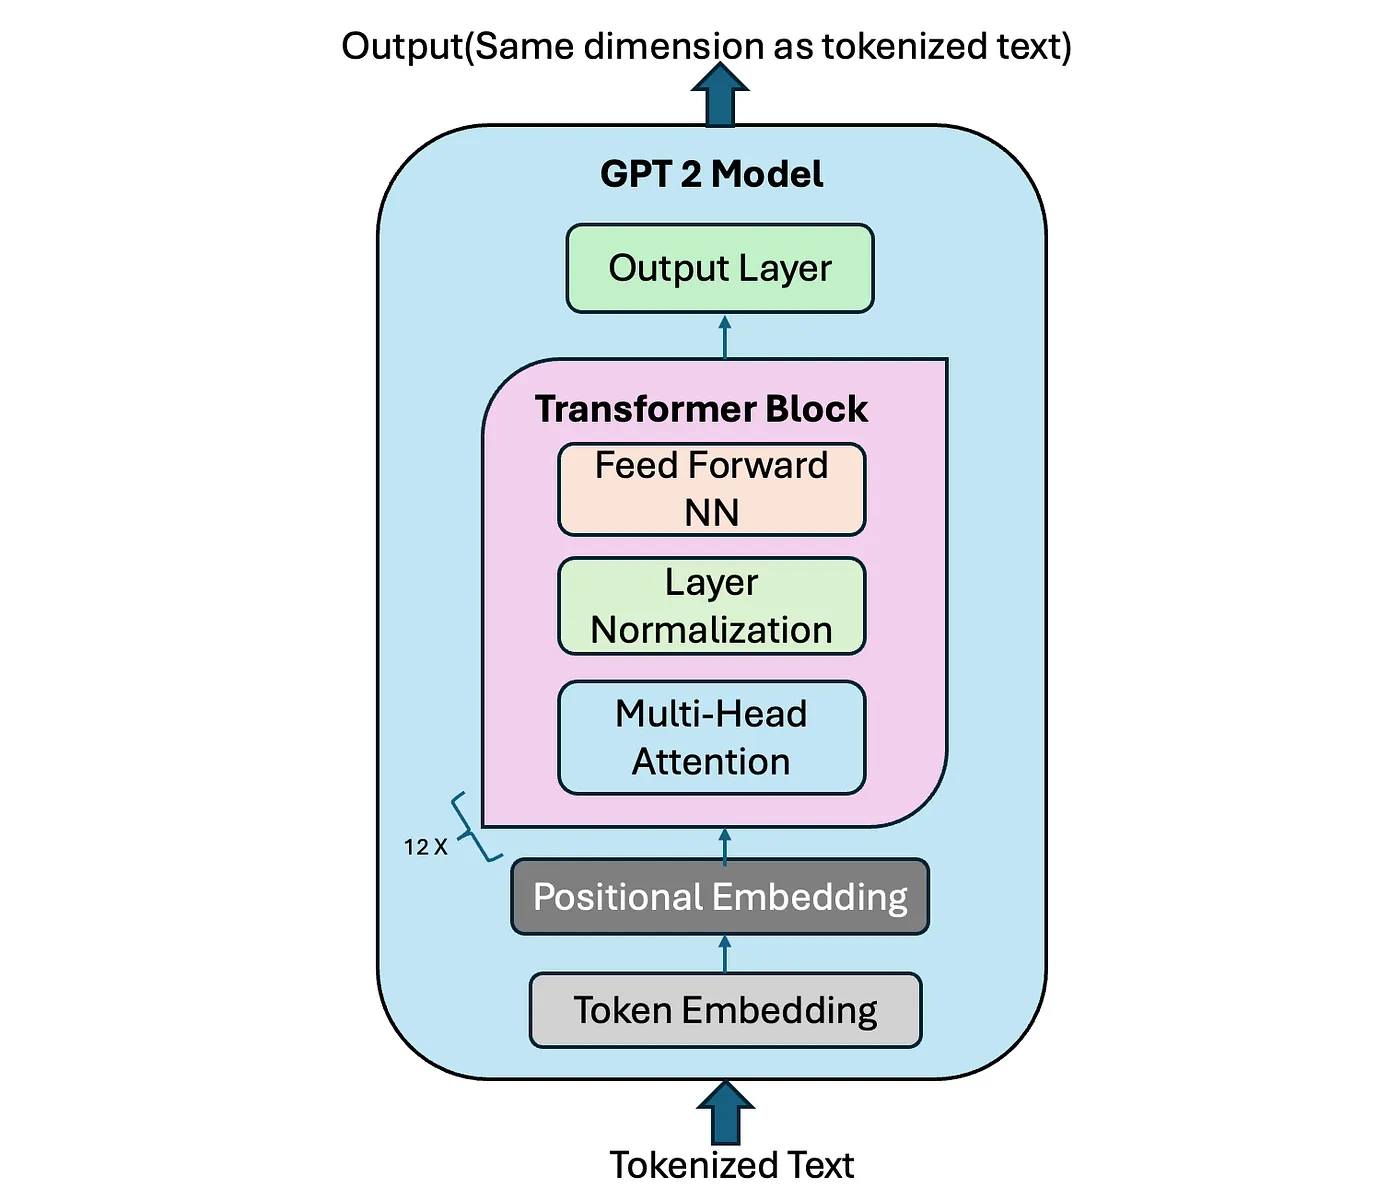

Ce notebook reprend les différentes parties du code du Transformer déjà implémenté dans le fichier `transformer.py`. Il y ajoute des affichages intermédiaires afin de faciliter la compréhension du fonctionnement du modèle, notamment des dimensions des tenseurs, des différentes étapes de calcul et du déroulement global de l’architecture.

In [2]:
import torch
import torch.nn as nn
import math

## 1 - Position Encoding :
Les Transformers ne prenant pas en compte la positions des tokens alors au enous traitons des données textuelles où l'ordre est primordial, il faudra donc 'injecter' cette information, nous construisons pour celà les encodages de position.
Nous adoptons le **Sinusoidal Encoding** proposé dans l'artcile Attention Is All You Need (Vaswani et al., 2017).


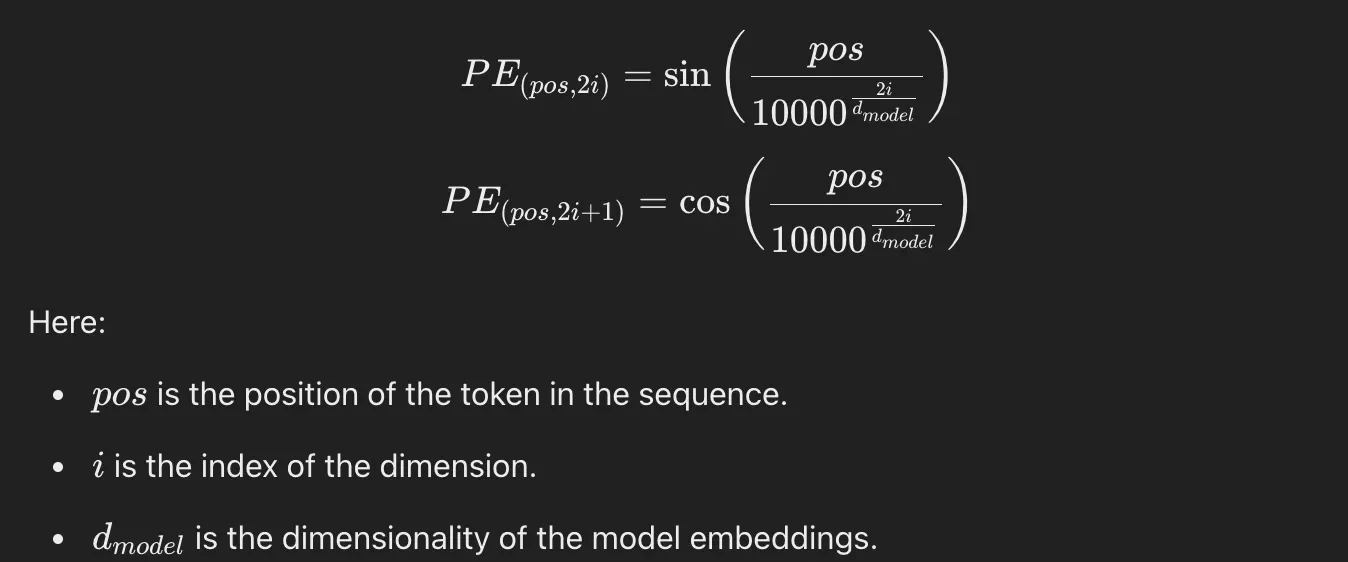

> **Remarque**
>
> Dans notre implémentation, (i) n’est pas considéré comme l’indice direct d’une dimension, mais comme l’indice d’une **paire de dimensions**.
>
> Pour une même valeur de (i), nous calculons :
>
> * une valeur sinusoïdale pour la dimension paire (2i) ;
> * une valeur cosinusoïdale pour la dimension impaire (2i+1).
>
> Par exemple, pour (i=0), les valeurs sont calculées pour les dimensions (0) et (1). Pour (i=1), elles sont calculées pour les dimensions (2) et (3), etc.
>
> Cette interprétation est directement intégrée dans l'implémentation.

In [9]:
class PositionalEncoding(nn.Module):
    def __init__(self, emb_size, max_seq_length=512):
        super().__init__()

        print("emb_size :", emb_size)
        print("max_seq_length :", max_seq_length)

        # Initialiser un tenseur pour les position encoding
        pe = torch.zeros(max_seq_length, emb_size)

        print("\n1. pe initial")
        print("Shape :", pe.shape)
        print(pe)

        # Création de tenseur de positions 
        # le unsqueeze est nécéssaire pour la multiplication par des div_terms plus bas
        position = torch.arange(0, max_seq_length, dtype=torch.float).unsqueeze(1)

        print("\n2. position")
        print("Shape :", position.shape)
        print(position)

        # On va représenter le 1/1000^(2*i/d_model), présent dans le calcul du sin et cos
        # équivalent à 1000^ -(2*i/d_model)
        # avec :
        # i : varie de 0 à d_model/2 -1, on peut aussi le voir comme une variable 
        # qui varie de 0 à d_model avec un pas de 2
        div_term = torch.exp(
            torch.arange(0, emb_size, 2).float() *
            - (math.log(1000.0) / emb_size)
        )

        print("\n3. div_term")
        print("Shape :", div_term.shape)
        print(div_term)

        print("\n4. position * div_term")
        print("Shape :", (position * div_term).shape)
        print(position * div_term)

        # Commencer à la position 0 et faire des pas de 2 (2i) ==> utiliser le sinus
        pe[:, 0::2] = torch.sin(position * div_term)

        print("\n5. pe après application du sinus")
        print("Shape :", pe.shape)
        print(pe)

        # Commencer à la position 1 et faire des pas de 2 (2i+1) ==> utiliser le cosinus
        pe[:, 1::2] = torch.cos(position * div_term)

        print("\n6. pe après application du cosinus")
        print("Shape :", pe.shape)
        print(pe)

        print("\n7. pe.unsqueeze(0)")
        print("Shape :", pe.unsqueeze(0).shape)
        print(pe.unsqueeze(0))

        # Enregistrer les encodages de positions en tant que buffer 
        # (ne sera pas considéré comme un paramètre du modèle)
        self.register_buffer('pe', pe.unsqueeze(0)) # Shape: (1, max_seq_length, emb_size)
    
        
    def forward(self, x) :
        print("\n8. Entrée x")
        print("Shape :", x.shape)
        print(x)

        print("\n9. x.size(1)")
        print(x.size(1))

        print("\n10. self.pe[:, :x.size(1)]")
        print("Shape :", self.pe[:, :x.size(1)].shape)
        print(self.pe[:, :x.size(1)])

        print("\n11. x + self.pe[:, :x.size(1)]")
        print("Shape :", (x + self.pe[:, :x.size(1)]).shape)
        print(x + self.pe[:, :x.size(1)])

        # x : Shape (batch_size, sequence_length, emb_size)
        # Ajouter l’encodage positionnel correspondant à la longueur réelle de la séquence.
        return x + self.pe[:, :x.size(1)]

In [10]:
# ---- EXEMPLE ----
positional_encoding = PositionalEncoding(
    emb_size=4,
    max_seq_length=5
)

x = torch.zeros(2, 3, 4)

resultat = positional_encoding(x)

emb_size : 4
max_seq_length : 5

1. pe initial
Shape : torch.Size([5, 4])
tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]])

2. position
Shape : torch.Size([5, 1])
tensor([[0.],
        [1.],
        [2.],
        [3.],
        [4.]])

3. div_term
Shape : torch.Size([2])
tensor([1.0000, 0.0316])

4. position * div_term
Shape : torch.Size([5, 2])
tensor([[0.0000, 0.0000],
        [1.0000, 0.0316],
        [2.0000, 0.0632],
        [3.0000, 0.0949],
        [4.0000, 0.1265]])

5. pe après application du sinus
Shape : torch.Size([5, 4])
tensor([[ 0.0000,  0.0000,  0.0000,  0.0000],
        [ 0.8415,  0.0000,  0.0316,  0.0000],
        [ 0.9093,  0.0000,  0.0632,  0.0000],
        [ 0.1411,  0.0000,  0.0947,  0.0000],
        [-0.7568,  0.0000,  0.1262,  0.0000]])

6. pe après application du cosinus
Shape : torch.Size([5, 4])
tensor([[ 0.0000,  1.0000,  0.0000,  1.0000],
        [ 0.8415,  0.5403,  0.0316,  0.

## 2 - Multi-head Attention :
Ce sera dans cette section que nous créerons les matrices de paramètres W_q, W_k et W_v. et que nous obtenerons la matrice d'attention.
Il y a ura pas mal de transformations matricielles (surtout dans les dimensions), il faudra donc être attentif !

In [1]:
class MultiHeadAttention(nn.Module):
    def __init__(self, emb_size, num_heads, qkv_bias=True):
        super().__init__()
        assert emb_size % num_heads == 0

        self.model_dim = emb_size
        self.num_heads = num_heads
        self.head_dim = emb_size // num_heads

        # Création des matrice de paramètres W_q, W_k et W_v
        # ce sont des matrices de dimensions (d_model x d_model)
        self.query = nn.Linear(
            self.model_dim,
            self.model_dim,
            bias=qkv_bias
        )

        self.key = nn.Linear(
            self.model_dim,
            self.model_dim,
            bias=qkv_bias
        )

        self.value = nn.Linear(
            self.model_dim,
            self.model_dim,
            bias=qkv_bias
        )

        print("\nDimensions des paramètres :")
        print("W_q, W_k et W_v :", self.query.weight.shape)

        if qkv_bias:
            print("b_q, b_k et b_v :", self.query.bias.shape)

        # La couche de sortie, à appliquer après avoir
        # concaténé les sorties de toutes les têtes d'attention
        self.out = nn.Linear(
            self.model_dim,
            self.model_dim,
            bias=False
        )

        print("W_o :", self.out.weight.shape)

    def forward(self, x, mask):
        print("\n\n========== FORWARD ==========")

        print("\n0. Tenseur d'entrée x")
        print("Shape :", x.shape)

        print("\nMasque reçu")
        print("Shape :", mask.shape)
        print(mask)

        # x : Shape (batch_size, seq_length, model_dim)
        batch_size, seq_length, _ = x.shape

        print("\nbatch_size :", batch_size)
        print("seq_length :", seq_length)
        print("model_dim  :", self.model_dim)

        # 1. Créer les matrices Q, K et V
        # Shape = shape de x = (batch_size, seq_length, model_dim)
        Q = self.query(x)
        K = self.key(x)
        V = self.value(x)

        print("\n1. Après les projections linéaires")

        print("\nQ, K et V")
        print("Shape :", Q.shape)

        # 2. Séparer en plusieurs têtes
        # Q, K et V seront : Shape (batch_size, seq_length, num_heads, model_dim)
        # Pour la suite des calculs on veut : Shape (batch_size, num_heads, seq_length, model_dim)
        Q = Q.view(
            batch_size,
            seq_length,
            self.num_heads,
            self.head_dim
        ).transpose(1, 2)

        print("\n2. Q, K et V après view et transpose")
        print("Pour rappel la shape voulue est [batch_size, num_heads, seq_length, model_dim]")
        print("Shape :", Q.shape)
        print(Q)

        K = K.view(
            batch_size,
            seq_length,
            self.num_heads,
            self.head_dim
        ).transpose(1, 2)

        V = V.view(
            batch_size,
            seq_length,
            self.num_heads,
            self.head_dim
        ).transpose(1, 2)

        print("\nK après transpose(-1, -2)")
        print("Shape :", K.transpose(-1, -2).shape)

        # 3. Calculer les scores
        scores = torch.matmul(
            Q,
            K.transpose(-1, -2)
        ) / math.sqrt(self.head_dim)

        print("\n3. Scores d'attention après QKᵀ / sqrt(head_dim)")
        print("Shape :", scores.shape)
        print(scores)

        # 4. appliquer le masque causal qui est passé en paramètre de la méthode
        # Il servira à masquer le futur
        # Les scores mis à -inf se transformeront en 0 apres le softmax
        scores = scores.masked_fill(
            mask == 0,
            float("-inf")
        )

        print("\n4. Scores après application du masque causal")
        print("Shape :", scores.shape)
        print(scores)

        # 5. matrice d'attention
        attention = torch.softmax(scores, dim=-1)

        print("\n5. Matrice d'attention après softmax")
        print("Shape :", attention.shape)
        print(attention)

        #print("\nSomme des poids sur la dernière dimension")
        #print(attention.sum(dim=-1))

        # 6. Calculer le Y = AV
        Y = torch.matmul(attention, V)

        print("\n6. Y = attention * V")
        print("Shape :", Y.shape)
        print(Y)

        print("\nY après transpose(1, 2), avant contiguous et view")
        print("Shape :", Y.transpose(1, 2).shape)
        print("Contigu :", Y.transpose(1, 2).is_contiguous())
        print(Y.transpose(1, 2))

        # 7. Concatener les resultats des différentes têtes
        # On revient à la shape des x : (batch_size, seq_length, model_dim)
        # on utilise .contiguous() pour réellement organiser les données selon
        # les nouvelles dimensions imposé par .transpose() juste avant
        Y = Y.transpose(1, 2).contiguous().view(
            batch_size,
            seq_length,
            self.model_dim
        )

        print("\n7. Y après concaténation des têtes")
        print("Shape :", Y.shape)
        print("Contigu :", Y.is_contiguous())
        print(Y)

        print("\n8. Résultat après la projection de sortie")
        print("Shape :", self.out(Y).shape)
        print(self.out(Y))

        return self.out(Y)

NameError: name 'nn' is not defined

In [10]:
# ---- TEST ----
torch.manual_seed(42) # pour la reproductibilité

# pour la lisbilité
torch.set_printoptions(
    precision=4,
    sci_mode=False
)

batch_size = 2
seq_length = 3
emb_size = 4
num_heads = 2

attention_layer = MultiHeadAttention(
    emb_size=emb_size,
    num_heads=num_heads
)

x = torch.arange(
    batch_size * seq_length * emb_size,
    dtype=torch.float32
).view(
    batch_size,
    seq_length,
    emb_size
)

x = x / 10

causal_mask = torch.tril(
    torch.ones(
        seq_length,
        seq_length
    )
)

causal_mask = causal_mask.unsqueeze(0).unsqueeze(0)

print("\n\n========== TEST ==========")

print("\nEntrée x :")
print("Shape :", x.shape)

print("\nMasque causal :")
print("Shape :", causal_mask.shape)
print(causal_mask)

result = attention_layer(
    x,
    causal_mask
)

print("\n\n========== RÉSULTAT FINAL ==========")
print("Shape :", result.shape)
print(result)


Dimensions des paramètres :
W_q, W_k et W_v : torch.Size([4, 4])
b_q, b_k et b_v : torch.Size([4])
W_o : torch.Size([4, 4])


========== TEST ==========

Entrée x :
Shape : torch.Size([2, 3, 4])

Masque causal :
Shape : torch.Size([1, 1, 3, 3])
tensor([[[[1., 0., 0.],
          [1., 1., 0.],
          [1., 1., 1.]]]])


========== FORWARD ==========

0. Tenseur d'entrée x
Shape : torch.Size([2, 3, 4])

Masque reçu
Shape : torch.Size([1, 1, 3, 3])
tensor([[[[1., 0., 0.],
          [1., 1., 0.],
          [1., 1., 1.]]]])

batch_size : 2
seq_length : 3
model_dim  : 4

1. Après les projections linéaires

Q, K et V
Shape : torch.Size([2, 3, 4])

2. Q, K et V après view et transpose
Pour rappel la shape voulue est [batch_size, num_heads, seq_length, model_dim]
Shape : torch.Size([2, 2, 3, 2])
tensor([[[[ 0.5413,  0.1234],
          [ 0.9971,  0.1400],
          [ 1.4529,  0.1566]],

         [[-0.1551,  0.1613],
          [ 0.0857,  0.4043],
          [ 0.3266,  0.6474]]],


        [[[ 1.

## Test Préparation des données 
Pour bien tester, nous allons préparer un fichier avec des phrases plus courtes que le max_seq_length et des phrases plus longues.

In [3]:
import torch 
from torch.nn.utils.rnn import pad_sequence


def prepare_gpt_dataset(
        filename,
        token_to_id,
        max_seq_length,
        pad_token="<pad>",
        unk_token="<unk>"
):

    pad_id = token_to_id[pad_token]
    unk_id = token_to_id[unk_token]

    examples = []

    with open(filename, "r", encoding="utf-8") as f:

        for line in f:
            tokens = line.strip().split()
            if len(tokens) == 0:
                continue

            ids = [token_to_id.get(tok, unk_id) for tok in tokens]

            ###################################################
            # Cas 1 : phrase plus courte que max_seq_length
            ###################################################

            if len(ids) <= max_seq_length:
                x = ids[:-1]
                y = ids[1:]
                x = x + [pad_id] * (max_seq_length - len(x))
                y = y + [pad_id] * (max_seq_length - len(y))
                examples.append(
                    (
                        torch.tensor(x),
                        torch.tensor(y)
                    )
                )

            ###################################################
            # Cas 2 : phrase longue
            ###################################################

            else:
                for i in range(len(ids) - max_seq_length):
                    x = ids[i:i+max_seq_length]
                    y = ids[i+1:i+max_seq_length+1]
                    examples.append(
                        (
                            torch.tensor(x),
                            torch.tensor(y)
                        )
                    )

    return examples

In [3]:
import json

data_filename = "train_data_test.txt"
tokenizer_filename = "../../data/bpe_embeddings/bpe_tokenizer_vocab_12k.json"
max_seq_length = 8

with open(tokenizer_filename, "r", encoding="utf-8") as f:
    data = json.load(f)

token_to_id = data["model"]["vocab"]

examples = prepare_gpt_dataset(
        data_filename,
        token_to_id,
        max_seq_length,
        pad_token="<pad>",
        unk_token="<unk>"
)

In [9]:
for example in examples :
    print(example)

print(type(examples[0]))

(tensor([    1,   235,  9654,    11,  1174,    12, 11828, 12000]), tensor([  235,  9654,    11,  1174,    12, 11828,     2, 12000]))
(tensor([   1,  668,  295, 1428,   38,  127, 9030, 8999]), tensor([ 668,  295, 1428,   38,  127, 9030, 8999,  161]))
(tensor([ 668,  295, 1428,   38,  127, 9030, 8999,  161]), tensor([ 295, 1428,   38,  127, 9030, 8999,  161,  176]))
(tensor([ 295, 1428,   38,  127, 9030, 8999,  161,  176]), tensor([1428,   38,  127, 9030, 8999,  161,  176,   11]))
(tensor([1428,   38,  127, 9030, 8999,  161,  176,   11]), tensor([  38,  127, 9030, 8999,  161,  176,   11,  240]))
(tensor([  38,  127, 9030, 8999,  161,  176,   11,  240]), tensor([ 127, 9030, 8999,  161,  176,   11,  240,   59]))
(tensor([ 127, 9030, 8999,  161,  176,   11,  240,   59]), tensor([9030, 8999,  161,  176,   11,  240,   59,  312]))
(tensor([9030, 8999,  161,  176,   11,  240,   59,  312]), tensor([8999,  161,  176,   11,  240,   59,  312,    2]))
(tensor([    1,   803,  3434,   261,  4091,    1

In [13]:
from torch.utils.data import DataLoader
train_loader = DataLoader(
    examples,
    batch_size=2,
    shuffle=True
)

first_batch = next(iter(train_loader))
x, y = first_batch
print(x.shape)
print(y.shape)
print(x)
print(y)

torch.Size([2, 8])
torch.Size([2, 8])
tensor([[    1,   803,  3434,   261,  4091,    13, 12000, 12000],
        [   38,   127,  9030,  8999,   161,   176,    11,   240]])
tensor([[  803,  3434,   261,  4091,    13,     2, 12000, 12000],
        [  127,  9030,  8999,   161,   176,    11,   240,    59]])


## Test d'entraînement

In [2]:
import torch
from torch.utils.data import DataLoader

from gpt import MyGPT
from hp import HP_GPT
import json
import utils

In [3]:
CONFIG_FILE = "configs/config_1_test.json"
hp = HP_GPT(CONFIG_FILE)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Device utilisé :", device)

model = MyGPT(hp)
model = model.to(device)
print(model)

tokenizer_filename = "../../data/bpe_embeddings/bpe_tokenizer_vocab_12k.json"
with open(tokenizer_filename, "r", encoding="utf-8") as f:
    data = json.load(f)

token_to_id = data["model"]["vocab"]

train_examples = prepare_gpt_dataset(
    filename=hp.train_filename,
    token_to_id=token_to_id,
    max_seq_length=hp.max_seq_length
)


val_examples = prepare_gpt_dataset(
    filename=hp.val_filename,
    token_to_id=token_to_id,
    max_seq_length=hp.max_seq_length
)


print(
    "Nombre exemples train :",
    len(train_examples)
)

print(
    "Nombre exemples val :",
    len(val_examples)
)

train_loader = DataLoader(
    train_examples,
    batch_size=hp.minibatch,
    shuffle=True
)


val_loader = DataLoader(
    val_examples,
    batch_size=hp.minibatch,
    shuffle=False
)

Device utilisé : cpu
vocab size (depuis fichier global) = 12001 emb_dim = 32
MyGPT(
  (E): Embedding(12001, 32, padding_idx=12000)
  (positional_encoding): PositionalEncoding()
  (blocks): ModuleList(
    (0-1): 2 x TransformerBlock(
      (mha): MultiHeadAttention(
        (query): Linear(in_features=32, out_features=32, bias=False)
        (key): Linear(in_features=32, out_features=32, bias=False)
        (value): Linear(in_features=32, out_features=32, bias=False)
        (out): Linear(in_features=32, out_features=32, bias=False)
      )
      (ff): FeedForward(
        (network): Sequential(
          (0): Linear(in_features=32, out_features=128, bias=True)
          (1): ReLU()
          (2): Linear(in_features=128, out_features=32, bias=True)
        )
      )
      (ln1): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
      (ln2): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (ln): LayerNorm((32,), eps=1e-05

In [4]:
exe_time, best_metrics = model.fit(
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=hp.nb_iter,
    strategy=hp.strategy,
    lr=1e-4,
    patience=3
)

Époque 1/10 | Train Loss: 0.0272 | Val Loss: 0.0244
 --> Nouveau best metrics détecté
Époque 2/10 | Train Loss: 0.0271 | Val Loss: 0.0243
 --> Nouveau best metrics détecté
Époque 3/10 | Train Loss: 0.0270 | Val Loss: 0.0242
 --> Nouveau best metrics détecté
Époque 4/10 | Train Loss: 0.0269 | Val Loss: 0.0242
 --> Nouveau best metrics détecté
Époque 5/10 | Train Loss: 0.0268 | Val Loss: 0.0241
 --> Nouveau best metrics détecté
Époque 6/10 | Train Loss: 0.0267 | Val Loss: 0.0240
 --> Nouveau best metrics détecté
Époque 7/10 | Train Loss: 0.0266 | Val Loss: 0.0240
 --> Nouveau best metrics détecté
Époque 8/10 | Train Loss: 0.0265 | Val Loss: 0.0239
 --> Nouveau best metrics détecté
Époque 9/10 | Train Loss: 0.0264 | Val Loss: 0.0238
 --> Nouveau best metrics détecté
Époque 10/10 | Train Loss: 0.0262 | Val Loss: 0.0237
 --> Nouveau best metrics détecté
-> Fichier .pt du Best Model enregistré avec succès.


In [5]:
best_metrics

{'train_loss': 0.0262421648216338,
 'val_loss': 0.02374169283815662,
 'gap': -0.0025004719834771823,
 'epoch': 10}

## Test strategie 2

In [6]:
CONFIG_FILE = "configs/config_2_test.json"
hp = HP_GPT(CONFIG_FILE)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Device utilisé :", device)

model = MyGPT(hp)
model = model.to(device)
print(model)

tokenizer_filename = "../../data/bpe_embeddings/bpe_tokenizer_vocab_12k.json"
with open(tokenizer_filename, "r", encoding="utf-8") as f:
    data = json.load(f)

token_to_id = data["model"]["vocab"]

train_examples = prepare_gpt_dataset(
    filename=hp.train_filename,
    token_to_id=model.vocab.dico_voca,
    max_seq_length=hp.max_seq_length
)


val_examples = prepare_gpt_dataset(
    filename=hp.val_filename,
    token_to_id=model.vocab.dico_voca,
    max_seq_length=hp.max_seq_length
)


print(
    "Nombre exemples train :",
    len(train_examples)
)

print(
    "Nombre exemples val :",
    len(val_examples)
)

train_loader = DataLoader(
    train_examples,
    batch_size=hp.minibatch,
    shuffle=True
)


val_loader = DataLoader(
    val_examples,
    batch_size=hp.minibatch,
    shuffle=False
)

Device utilisé : cpu
strategy = 2
emb_filename = ../../data/bpe_embeddings/bpe_embeddings_12k_32.txt
Taille annoncée dans le fichier : 11844
Tokens réellement lus : 11844
Taille finale du vocabulaire : 11846
unk_id : 11844
pad_id : 11845
Forme de la matrice : torch.Size([11846, 32])
MyGPT(
  (E): Embedding(11846, 32, padding_idx=11845)
  (positional_encoding): PositionalEncoding()
  (blocks): ModuleList(
    (0-1): 2 x TransformerBlock(
      (mha): MultiHeadAttention(
        (query): Linear(in_features=32, out_features=32, bias=False)
        (key): Linear(in_features=32, out_features=32, bias=False)
        (value): Linear(in_features=32, out_features=32, bias=False)
        (out): Linear(in_features=32, out_features=32, bias=False)
      )
      (ff): FeedForward(
        (network): Sequential(
          (0): Linear(in_features=32, out_features=128, bias=True)
          (1): ReLU()
          (2): Linear(in_features=128, out_features=32, bias=True)
        )
      )
      (ln1): Lay

In [7]:
exe_time, best_metrics = model.fit(
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=hp.nb_iter,
    strategy=hp.strategy,
    lr=1e-4,
    patience=3
)

best_metrics

Époque 1/10 | Train Loss: 0.0271 | Val Loss: 0.0243
 --> Nouveau best metrics détecté
Époque 2/10 | Train Loss: 0.0270 | Val Loss: 0.0243
 --> Nouveau best metrics détecté
Époque 3/10 | Train Loss: 0.0269 | Val Loss: 0.0242
 --> Nouveau best metrics détecté
Époque 4/10 | Train Loss: 0.0268 | Val Loss: 0.0241
 --> Nouveau best metrics détecté
Époque 5/10 | Train Loss: 0.0267 | Val Loss: 0.0241
 --> Nouveau best metrics détecté
Époque 6/10 | Train Loss: 0.0266 | Val Loss: 0.0240
 --> Nouveau best metrics détecté
Époque 7/10 | Train Loss: 0.0265 | Val Loss: 0.0239
 --> Nouveau best metrics détecté
Époque 8/10 | Train Loss: 0.0264 | Val Loss: 0.0239
 --> Nouveau best metrics détecté
Époque 9/10 | Train Loss: 0.0263 | Val Loss: 0.0238
 --> Nouveau best metrics détecté
Époque 10/10 | Train Loss: 0.0262 | Val Loss: 0.0237
 --> Nouveau best metrics détecté
-> Fichier .pt du Best Model enregistré avec succès.


{'train_loss': 0.02619221064647604,
 'val_loss': 0.023737592770315497,
 'gap': -0.0024546178761605426,
 'epoch': 10}

## Test REAL

In [1]:
CONFIG_FILE = "configs/config_1.json"
hp = HP_GPT(CONFIG_FILE)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Device utilisé :", device)

model = MyGPT(hp)
model = model.to(device)

print(model)

tokenizer_filename = "../../data/bpe_embeddings/bpe_tokenizer_vocab_12k.json"
with open(tokenizer_filename, "r", encoding="utf-8") as f:
    data = json.load(f)

token_to_id = data["model"]["vocab"]

train_examples = prepare_gpt_dataset(
    filename=hp.train_filename,
    token_to_id=model.vocab.dico_voca,
    max_seq_length=hp.max_seq_length
)


val_examples = prepare_gpt_dataset(
    filename=hp.val_filename,
    token_to_id=token_to_id,
    max_seq_length=hp.max_seq_length
)


print(
    "Nombre exemples train :",
    len(train_examples)
)

print(
    "Nombre exemples val :",
    len(val_examples)
)

train_loader = DataLoader(
    train_examples,
    batch_size=hp.minibatch,
    shuffle=True
)


val_loader = DataLoader(
    val_examples,
    batch_size=hp.minibatch,
    shuffle=False
)

NameError: name 'HP_GPT' is not defined

In [7]:
exe_time, best_metrics = model.fit(
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=hp.nb_iter,
    strategy=hp.strategy,
    lr=1e-4,
    patience=3
)

KeyboardInterrupt: 